# Coastal elevation — DeltaDTM and GEM-15 (Google Earth Engine)

Downloads two bare-earth elevation models for one country and writes one GeoTIFF each, for the bathtub notebook:

| Source | Producer | Native resolution | Coverage | Vertical datum |
|---|---|---|---|---|
| DeltaDTM v1 | Deltares (Pronk et al., 2024) | 1″ (~30 m) | coastal land 0–10 m only | EGM2008 |
| GEM-15 v1 (`dtm` band) | Google Research (2026, experimental) | 15 m | all land | EGM96 |

Both are exported on the same 1″ (~30 m) grid in EPSG:4326. Sea, lakes and, for DeltaDTM, land above 10 m are written as
no data (−9999).

Requirements:
- Earth Engine access and a Google Cloud project ID in `.env` (`GEE_PROJECT`);
- packages: `earthengine-api`, `requests`, `rasterio`, `gigaspatial`.

In [1]:
# Environment: PROJ database, warnings and log messages off
import os
import sys
import logging
import warnings
from pathlib import Path

proj_dir = str(Path(sys.prefix) / "share" / "proj")
os.environ["PROJ_DATA"] = proj_dir
os.environ["PROJ_LIB"] = proj_dir
os.environ["PYTHONWARNINGS"] = "ignore"
import pyproj
pyproj.datadir.set_data_dir(proj_dir)

warnings.filterwarnings("ignore")
logging.disable(logging.WARNING)

In [2]:
import shutil
import tempfile

import numpy as np
import requests
import rasterio
from rasterio.merge import merge as rio_merge
import geopandas as gpd
import matplotlib.pyplot as plt
import ee
from dotenv import load_dotenv
from gigaspatial.handlers import AdminBoundaries

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
load_dotenv(PROJECT / ".env")   # GEE project ID (never printed)

CONFIG = {
    "country_iso3": "CUB",
    "margin_deg": 0.1,                    # same margin as the bathtub notebook
    "res_as": 1,                          # export resolution, arc-seconds (~30 m)
    "tile_deg": 0.5,                      # download tile size (< 32 MB per request)
    "nodata": -9999,
    "out_dir": PROJECT / "data/dem",
    "sources": {
        "deltadtm": {"asset": "users/maartenpronk/deltadtm/v1", "band": None},
        "gem15":    {"asset": "projects/climate-and-sustainability/assets/gem-15_v1", "band": "dtm"},
    },
}
CONFIG["out_dir"].mkdir(parents=True, exist_ok=True)
ISO = CONFIG["country_iso3"]

## 1. Earth Engine login

The first time, `ee.Authenticate()` opens a browser window to log in. The token is then stored on the computer.

In [3]:
try:
    ee.Initialize(project=os.environ["GEE_PROJECT"])
except Exception:
    ee.Authenticate()
    ee.Initialize(project=os.environ["GEE_PROJECT"])
print("Earth Engine ready")

Earth Engine ready


## 2. Area

Country bounding box from GigaSpatial, plus a 0.1° margin, as in the bathtub notebook.

In [4]:
country = gpd.GeoSeries(
    [AdminBoundaries.create(country_code=ISO).to_geoms()[0]], crs="EPSG:4326")
m = CONFIG["margin_deg"]
west, south, east, north = country.total_bounds + np.array([-m, -m, m, m])
print(f"{ISO} box: lon {west:.2f} to {east:.2f}, lat {south:.2f} to {north:.2f}")

CUB box: lon -85.05 to -74.03, lat 19.73 to 23.38


## 3. Download

Each source is read as a mosaic over the area, masked pixels are set to −9999, and the image is downloaded in tiles of
0.5° on a global 1″ grid (so that tiles line up exactly), then merged into one GeoTIFF.

In [5]:
RES = CONFIG["res_as"] / 3600
GRID = [RES, 0, -180, 0, -RES, 90]       # global grid aligned on whole arc-seconds


def load_image(asset, band):
    """Image or mosaic of an image collection over the area."""
    kind = ee.data.getAsset(asset)["type"]
    box = ee.Geometry.Rectangle([west, south, east, north])
    img = ee.ImageCollection(asset).filterBounds(box).mosaic() if kind == "IMAGE_COLLECTION" else ee.Image(asset)
    img = img.select(band) if band else img.select(0)
    return img.unmask(CONFIG["nodata"]).toFloat()


def download(name, asset, band):
    out = CONFIG["out_dir"] / f"{ISO}_{name}.tif"
    if out.exists():
        print(f"{out.name}: already there")
        return out
    img = load_image(asset, band)
    tmp = Path(tempfile.mkdtemp())
    step = CONFIG["tile_deg"]
    xs, ys = np.arange(west, east, step), np.arange(south, north, step)
    tiles = []
    for i, x in enumerate(xs):
        for j, y in enumerate(ys):
            rect = ee.Geometry.Rectangle([x, y, min(x + step, east), min(y + step, north)])
            url = img.getDownloadURL({"region": rect, "crs": "EPSG:4326", "crs_transform": GRID,
                                      "format": "GEO_TIFF"})
            f = tmp / f"t_{i}_{j}.tif"
            r = requests.get(url, timeout=300)
            r.raise_for_status()
            f.write_bytes(r.content)
            tiles.append(f)
    srcs = [rasterio.open(f) for f in tiles]
    mosaic, transform = rio_merge(srcs, nodata=CONFIG["nodata"])
    profile = srcs[0].profile.copy()
    for s in srcs:
        s.close()
    profile.update(driver="GTiff", height=mosaic.shape[1], width=mosaic.shape[2], transform=transform,
                   nodata=CONFIG["nodata"], compress="deflate", tiled=True)
    with rasterio.open(out, "w", **profile) as dst:
        dst.write(mosaic)
    shutil.rmtree(tmp)
    print(f"{out.name}: {len(tiles)} tiles, {mosaic.shape[2]} x {mosaic.shape[1]} px")
    return out


FILES = {name: download(name, s["asset"], s["band"]) for name, s in CONFIG["sources"].items()}

CUB_deltadtm.tif: 184 tiles, 39677 x 13147 px
CUB_gem15.tif: 184 tiles, 39677 x 13147 px


## 4. Check

Range of values on land and a quick map of each file.

deltadtm  min   -2.0 m | median  10.0 m | max    10.0 m | valid 23.5% of pixels
gem15     min  -52.2 m | median  50.4 m | max  1965.1 m | valid 23.6% of pixels


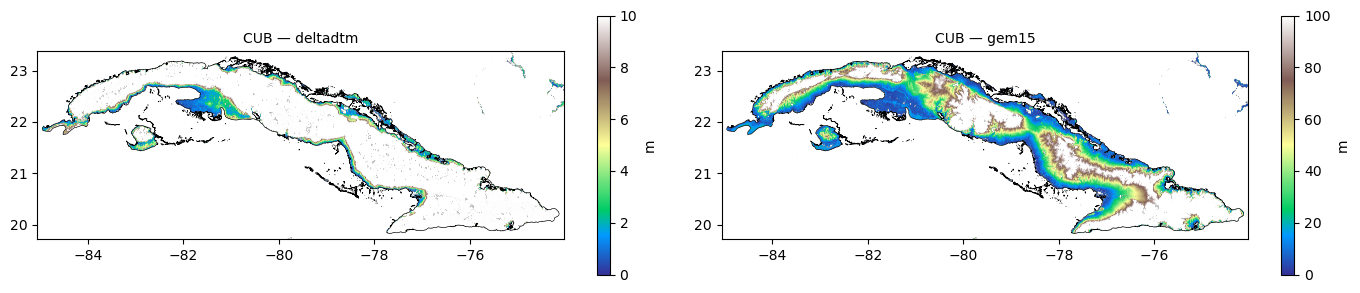

In [6]:
fig, axes = plt.subplots(1, len(FILES), figsize=(7 * len(FILES), 4))
for ax, (name, f) in zip(np.atleast_1d(axes), FILES.items()):
    with rasterio.open(f) as src:
        a = src.read(1, masked=True)
        ext = [src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top]
    print(f"{name:9s} min {a.min():6.1f} m | median {np.ma.median(a):5.1f} m | max {a.max():7.1f} m "
          f"| valid {100 * a.count() / a.size:4.1f}% of pixels")
    im = ax.imshow(a, extent=ext, cmap="terrain", vmin=0, vmax=10 if name == "deltadtm" else 100)
    country.boundary.plot(ax=ax, color="k", linewidth=0.4)
    ax.set_title(f"{ISO} — {name}", fontsize=10)
    fig.colorbar(im, ax=ax, shrink=0.7, label="m")
plt.tight_layout()
plt.show()